## Interval Analysis

In [18]:
!pip install tensorboardX


In [19]:
!pip install matplotlib

In [20]:
!pip install torchvision

In [21]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128
Note: you may need to restart the kernel to use updated packages.


In [22]:
import torch
print(torch.__version__, torch.cuda.is_available())

2.11.0+cu128 True


In [23]:
import torch

print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

2.11.0+cu128
12.8
True


In [24]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 100

np.random.seed(42)
torch.manual_seed(42)

train_dataset = datasets.MNIST('mnist_data/', train=True, download=True,
                               transform=transforms.ToTensor())
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True,
                              transform=transforms.ToTensor())

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [25]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        dims = [784, 50, 50, 50, 10]
        self.linears = nn.ModuleList([nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:])])

    def forward(self, x):
        x = x.view(x.size(0), -1)
        for lin in self.linears[:-1]:
            x = F.relu(lin(x))
        return self.linears[-1](x)

def clean_accuracy(model):
    ok = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            ok += (model(x).argmax(1) == y).sum().item()
    return 100 * ok / len(test_dataset)

In [26]:
def spec_lower_bounds(model, x, y, eps):
    lo = (x - eps).clamp(0, 1).flatten(1)
    hi = (x + eps).clamp(0, 1).flatten(1)
    for lin in model.linears[:-1]:
        mu, r = (hi + lo) / 2, (hi - lo) / 2
        mu, r = lin(mu), r @ lin.weight.abs().T
        lo, hi = F.relu(mu - r), F.relu(mu + r)
    last = model.linears[-1]
    C = F.one_hot(y, 10).float().unsqueeze(1) - torch.eye(10, device=x.device)
    CW, Cb = C @ last.weight, C @ last.bias
    mu, r = (hi + lo) / 2, (hi - lo) / 2
    return torch.einsum('bjk,bk->bj', CW, mu) + Cb - torch.einsum('bjk,bk->bj', CW.abs(), r)

def ibp_loss(model, x, y, eps, kappa):
    fit = F.cross_entropy(model(x), y)
    spec = F.cross_entropy(-spec_lower_bounds(model, x, y, eps), y)
    return kappa * fit + (1 - kappa) * spec

@torch.no_grad()
def verified_mask(model, x, y, eps):
    lower = spec_lower_bounds(model, x, y, eps).masked_fill(F.one_hot(y, 10).bool(), float('inf'))
    return lower.min(1).values > 0

@torch.no_grad()
def verified_accuracy(model, eps):
    ok = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        ok += verified_mask(model, x, y, eps).sum().item()
    return 100 * ok / len(test_dataset)

In [27]:
def sync():
    if device.type == "cuda": torch.cuda.synchronize()

def train(model, epochs=30, ibp=False, eps_train=0.1, kappa_end=0.5,
          warmup=2, ramp=15, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    spe, step = len(train_loader), 0
    sync(); t0 = time.time()
    for ep in range(epochs):
        total = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if ibp:
                t = min(max((step - warmup * spe) / (ramp * spe), 0.0), 1.0)
                loss = ibp_loss(model, x, y, eps=t * eps_train, kappa=1 - t * (1 - kappa_end))
            else:
                loss = F.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            step += 1; total += loss.item()
        print(f"epoch {ep+1}: loss {total/spe:.4f}")
    sync(); return time.time() - t0

In [28]:
def pgd_linf(model, x, y, eps, steps=50):
    alpha = 2.5 * eps / steps
    delta = (torch.rand_like(x) * 2 - 1) * eps
    delta = (x + delta).clamp(0, 1) - x
    for _ in range(steps):
        delta.requires_grad_(True)
        grad, = torch.autograd.grad(F.cross_entropy(model(x + delta), y), delta)
        delta = (delta.detach() + alpha * grad.sign()).clamp(-eps, eps)
        delta = (x + delta).clamp(0, 1) - x
    return (x + delta).detach()

def pgd_accuracy(model, eps, steps=50):
    ok = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        x_adv = pgd_linf(model, x, y, eps, steps)
        with torch.no_grad():
            ok += ((model(x).argmax(1) == y) & (model(x_adv).argmax(1) == y)).sum().item()
    return 100 * ok / len(test_dataset)

In [29]:
EPOCHS = 30
std_model = MLP().to(device); t_std = train(std_model, EPOCHS)
ibp_model = MLP().to(device); t_ibp = train(ibp_model, EPOCHS, ibp=True)

print(f"training time: standard {t_std:.0f}s, IBP {t_ibp:.0f}s ({t_ibp/t_std:.1f}x)")
for name, m in [("standard", std_model), ("IBP", ibp_model)]:
    print(f"{name}: clean {clean_accuracy(m):.2f}%, PGD (eps=0.1) {pgd_accuracy(m, 0.1):.2f}%")

epoch 1: loss 0.4946
epoch 2: loss 0.2072
epoch 3: loss 0.1551
epoch 4: loss 0.1251
epoch 5: loss 0.1056
epoch 6: loss 0.0945
epoch 7: loss 0.0836
epoch 8: loss 0.0738
epoch 9: loss 0.0660
epoch 10: loss 0.0606
epoch 11: loss 0.0537
epoch 12: loss 0.0503
epoch 13: loss 0.0442
epoch 14: loss 0.0396
epoch 15: loss 0.0383
epoch 16: loss 0.0321
epoch 17: loss 0.0301
epoch 18: loss 0.0273
epoch 19: loss 0.0243
epoch 20: loss 0.0240
epoch 21: loss 0.0203
epoch 22: loss 0.0214
epoch 23: loss 0.0191
epoch 24: loss 0.0176
epoch 25: loss 0.0159
epoch 26: loss 0.0172
epoch 27: loss 0.0158
epoch 28: loss 0.0163
epoch 29: loss 0.0135
epoch 30: loss 0.0123
epoch 1: loss 0.5238
epoch 2: loss 0.2220
epoch 3: loss 0.1957
epoch 4: loss 0.2354
epoch 5: loss 0.2420
epoch 6: loss 0.2458
epoch 7: loss 0.2530
epoch 8: loss 0.2662
epoch 9: loss 0.2829
epoch 10: loss 0.3013
epoch 11: loss 0.3235
epoch 12: loss 0.3484
epoch 13: loss 0.3799
epoch 14: loss 0.4146
epoch 15: loss 0.4525
epoch 16: loss 0.4935
epoch 

eps 0.01: verified 94.32%
eps 0.02: verified 93.60%
eps 0.03: verified 92.79%
eps 0.04: verified 91.76%
eps 0.05: verified 90.63%
eps 0.06: verified 89.02%
eps 0.07: verified 87.40%
eps 0.08: verified 85.47%
eps 0.09: verified 83.51%
eps 0.10: verified 80.93%


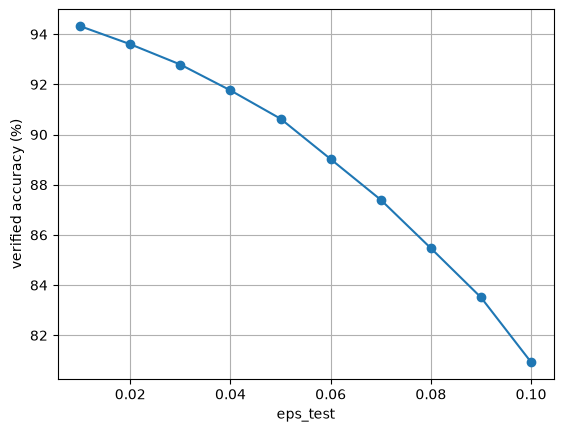

In [30]:
epsilons = torch.linspace(0.01, 0.1, 10).tolist()
ver = [verified_accuracy(ibp_model, e) for e in epsilons]
for e, v in zip(epsilons, ver): print(f"eps {e:.2f}: verified {v:.2f}%")

plt.plot(epsilons, ver, marker='o')
plt.xlabel('eps_test'); plt.ylabel('verified accuracy (%)'); plt.grid(True); plt.show()

eps 0.01: uncertified 80, PGD found adversarial 72, unresolved 8
eps 0.02: uncertified 152, PGD found adversarial 130, unresolved 22
eps 0.03: uncertified 233, PGD found adversarial 186, unresolved 47
eps 0.04: uncertified 336, PGD found adversarial 255, unresolved 81
eps 0.05: uncertified 449, PGD found adversarial 344, unresolved 105
eps 0.06: uncertified 610, PGD found adversarial 454, unresolved 156
eps 0.07: uncertified 772, PGD found adversarial 551, unresolved 221
eps 0.08: uncertified 965, PGD found adversarial 666, unresolved 299
eps 0.09: uncertified 1161, PGD found adversarial 785, unresolved 376
eps 0.10: uncertified 1419, PGD found adversarial 916, unresolved 503


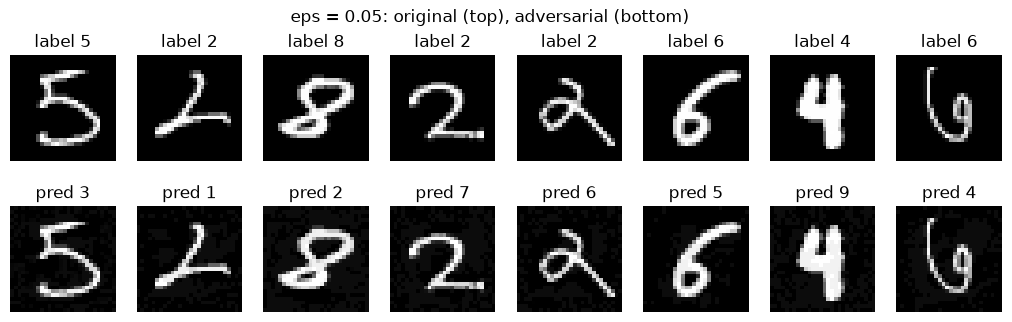

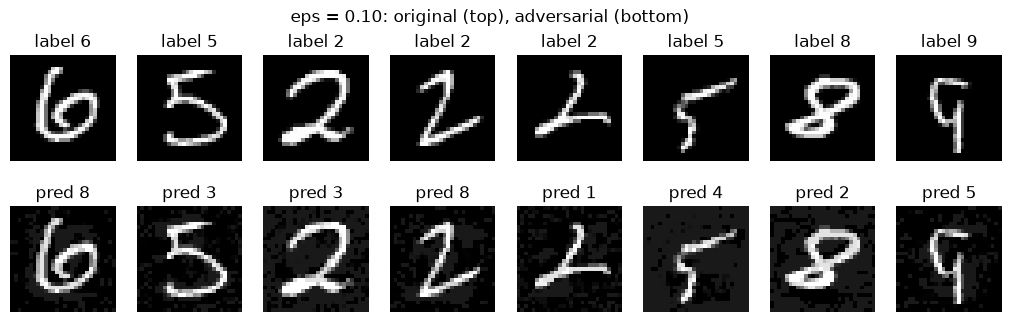

In [31]:
def find_adversarials(model, eps, keep=8):
    n_unver = n_adv = 0; ex = []
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        with torch.no_grad():
            clean = model(x).argmax(1) == y
        unver = clean & ~verified_mask(model, x, y, eps)
        x_adv = pgd_linf(model, x, y, eps)
        with torch.no_grad():
            pred = model(x_adv).argmax(1)
        found = unver & (pred != y)
        n_unver += unver.sum().item(); n_adv += found.sum().item()
        for i in found.nonzero().flatten().tolist():
            if len(ex) < keep:
                ex.append((x[i].cpu(), x_adv[i].cpu(), y[i].item(), pred[i].item()))
    return n_unver, n_adv, ex

examples = {}
for e in epsilons:
    nu, na, examples[e] = find_adversarials(ibp_model, e)
    print(f"eps {e:.2f}: uncertified {nu}, PGD found adversarial {na}, unresolved {nu - na}")

def show(ex, eps):
    if not ex: print("none found"); return
    fig, ax = plt.subplots(2, len(ex), figsize=(1.6 * len(ex), 3.6), squeeze=False)
    for j, (x0, xa, y, p) in enumerate(ex):
        ax[0, j].imshow(x0[0], cmap='gray', vmin=0, vmax=1); ax[0, j].set_title(f"label {y}")
        ax[1, j].imshow(xa[0], cmap='gray', vmin=0, vmax=1); ax[1, j].set_title(f"pred {p}")
        ax[0, j].axis('off'); ax[1, j].axis('off')
    fig.suptitle(f"eps = {eps:.2f}: original (top), adversarial (bottom)"); plt.show()

show(examples[epsilons[4]], epsilons[4])
show(examples[epsilons[-1]], epsilons[-1])

### Write the interval analysis for the simple model

In [ ]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

def ibp_linear(layer, l, u):
    W, b = layer.weight, layer.bias
    Wp, Wn = W.clamp(min=0), W.clamp(max=0)
    return l @ Wp.T + u @ Wn.T + b, u @ Wp.T + l @ Wn.T + b

@torch.no_grad()
def verify_batch(model, x, y, eps):
    """True where robustness is proven for the l_inf ball of radius eps."""
    net = model[1]
    x = x.view(-1, 28*28)
    # input box, clipped to valid pixel range
    l, u = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)
    # Normalize (increasing map, so apply to both bounds)
    l, u = (l - 0.1307) / 0.3081, (u - 0.1307) / 0.3081
    # fc + ReLU
    l, u = ibp_linear(net.fc, l, u)
    l, u = l.clamp(min=0), u.clamp(min=0)
    # fc2 -> logit bounds (skip softmax: it is monotonic, argmax unchanged)
    l, u = ibp_linear(net.fc2, l, u)
    # spec layer: row j of C is e_y - e_j (row j=y is all zeros)
    C = F.one_hot(y, 10).float()[:, None, :] - torch.eye(10, device=x.device)[None]
    lower = (torch.einsum('bjk,bk->bj', C.clamp(min=0), l)
             + torch.einsum('bjk,bk->bj', C.clamp(max=0), u))
    return (lower >= 0).all(dim=1)

def verified_accuracy(model, eps):
    model.eval()
    ok = total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            correct = model(images).argmax(1) == labels  # guards against ties
            ok += (verify_batch(model, images, labels, eps) & correct).sum().item()
            total += labels.size(0)
    return 100 * ok / total

In [ ]:
epsilons = torch.linspace(0.01, 0.1, 10).tolist()
results = []
print(f"{'eps':>6} | verified acc (%)")
for eps in epsilons:
    va = verified_accuracy(model, eps)
    results.append(va)
    print(f"{eps:6.2f} | {va:6.2f}")

plt.figure(figsize=(6, 4))
plt.plot(epsilons, results, marker='o')
plt.xlabel('epsilon (l_inf radius)')
plt.ylabel('verified accuracy (%)')
plt.title('Interval analysis: verified accuracy vs epsilon')
plt.grid(True)
plt.show()